# 07 - Results Visualization

**Project:** Causal ML for Climate Policy Effectiveness
**Purpose:** Produce the manuscript's figures. Figures 2 and 3 (naive-agreement
and sensitivity-summary) are already generated by Notebooks 05/06 directly;
this notebook only adds Figure 1 (treatment adoption coverage), since that is
the one figure not already produced as a side effect of the estimation
notebooks.

**Input:** `data/processed/treatment_matrix.csv`
**Output:** `outputs/figures/fig1_adoption_timeline.png`

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.visualization import set_publication_style, save_figure, COLORS

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
set_publication_style()

---
## Figure 1: Carbon-Pricing Adoption Timeline

Number of countries with an active carbon tax or ETS instrument in place each
year, 1990-2022, from the World Carbon Pricing Database (Dolphin & Xiahou
2022) treatment construction (Notebook 02).

  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\fig1_adoption_timeline.png


  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\fig1_adoption_timeline.pdf


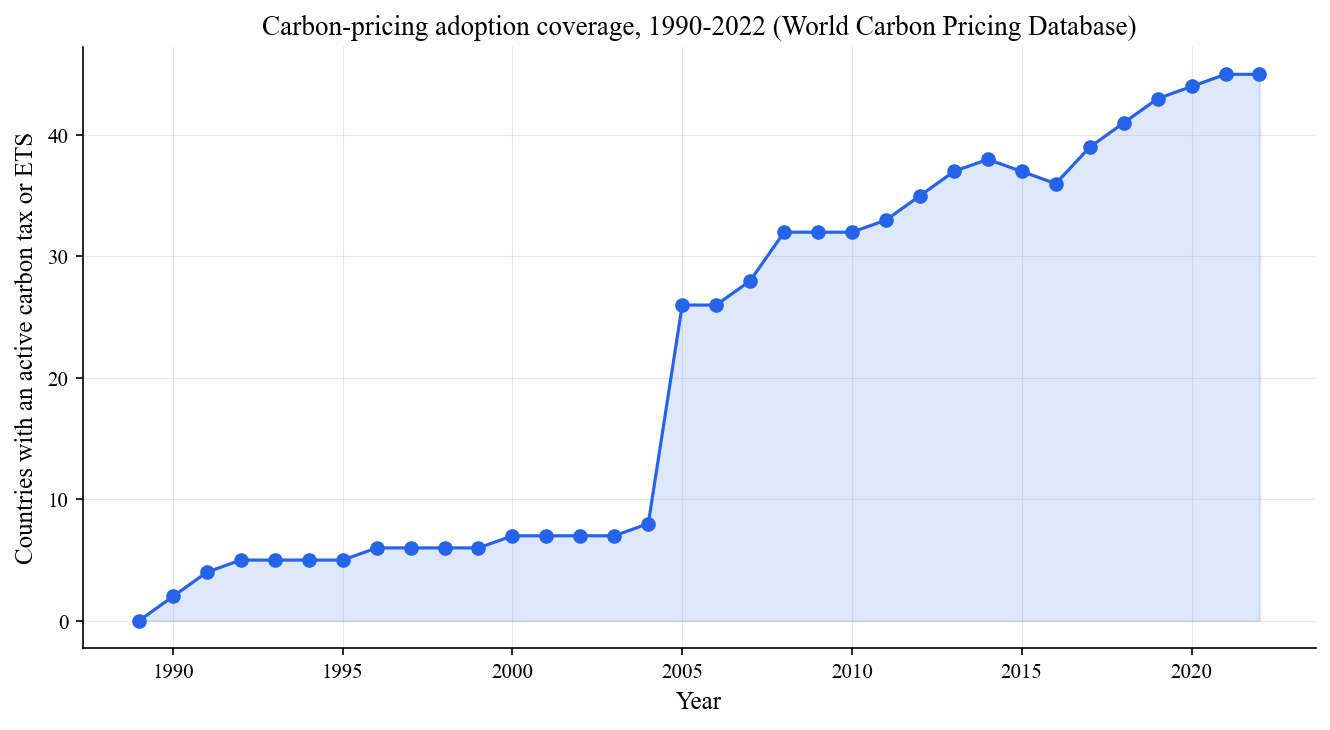

Ever-treated by 2022: 46 countries
Countries treated by end of panel (2022): 45


In [2]:
treatment_df = pd.read_csv(PROCESSED_DIR / "treatment_matrix.csv")

coverage_by_year = treatment_df.groupby("year")["treat_carbon_price"].sum()
coverage_by_year = coverage_by_year[coverage_by_year.index <= 2022]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(coverage_by_year.index, coverage_by_year.values, marker="o", color=COLORS["primary"])
ax.fill_between(coverage_by_year.index, coverage_by_year.values, alpha=0.15, color=COLORS["primary"])
ax.set_xlabel("Year")
ax.set_ylabel("Countries with an active carbon tax or ETS")
ax.set_title("Carbon-pricing adoption coverage, 1990-2022 (World Carbon Pricing Database)")
plt.tight_layout()
save_figure(fig, "fig1_adoption_timeline")
plt.show()

n_ever_treated = treatment_df.loc[treatment_df["treat_carbon_price"] == 1, "iso3"].nunique()
print(f"Ever-treated by 2022: {n_ever_treated} countries")
print(f"Countries treated by end of panel (2022): {int(coverage_by_year.iloc[-1])}")

---
## Note on Figures 2-3

Figure 2 (`fig_naive_agreement`, produced by Notebook 05) shows the naive
Sun-Abraham event study alongside the Callaway-Santanna overall ATT -- the
headline-looking result.

Figure 3 (`fig_sensitivity_summary`, produced by Notebook 06) shows the
naive event study next to the unit-specific-trends version, the paper's main
visual evidence that the naive effect does not survive sensitivity checks.

Both already exist in `outputs/figures/` from running Notebooks 05 and 06;
listed here for completeness rather than regenerated.

In [3]:
import os
for name in ["fig_naive_agreement", "fig_sensitivity_summary", "fig1_adoption_timeline"]:
    path = FIG_DIR / f"{name}.png"
    status = "OK" if path.exists() else "MISSING"
    print(f"  {name}.png: {status}")

print()
print("All figures generated")
print("Proceed to Notebook 08: Table Export")

  fig_naive_agreement.png: OK
  fig_sensitivity_summary.png: OK
  fig1_adoption_timeline.png: OK

All figures generated
Proceed to Notebook 08: Table Export
